# Olist Analysis: Product Categories (Part A) and Payments (Part B)

**Part A (Sales team):** which categories have the highest demand and the highest sales value?
**Part B (Finance team):** which payment methods do customers use, and is the payment amount related to the installments?

**Definitions**
- **Items sold:** number of rows in `order_items`. **Product sales:** `SUM(price)` (not profit, freight excluded).
- **Payment record:** one row in `payments`. An order can have several records, so records and orders are counted separately.
- Prices are in Brazilian reais (R$).

In [63]:
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.float_format", "{:,.2f}".format)

# Cleaned tables (Data/Processed)
products = pd.read_parquet("../Data/Processed/products_clean.parquet")
orders = pd.read_parquet("../Data/Processed/orders_clean.parquet")

# No cleaned version of these two tables is in the repository, so the raw files are used (Data/Raw)
order_items = pd.read_parquet("../Data/Processed/order_items_clean.parquet")
payments = pd.read_parquet("../Data/Processed/payments_clean.parquet")

# The one cleaning step of the team for payments: 0 installments is invalid, so it becomes missing
payments.loc[payments["payment_installments"] == 0, "payment_installments"] = None

## Part A: Product Categories

### A0. Data preparation

In [64]:
# Add the category to every sold item. Missing category -> "unknown" (we keep these items).
items = order_items.merge(products[["product_id", "product_category_name"]], on="product_id", how="left")
items["category"] = items["product_category_name"].fillna("unknown")

# The join must not change the number of rows or the total price
print("Rows:", len(order_items), "->", len(items))
print("Total price:", round(order_items["price"].sum(), 2), "->", round(items["price"].sum(), 2))

# One row per category
cat = items.groupby("category").agg(items_sold=("price", "size"), sales=("price", "sum"),
                                    avg_price=("price", "mean"), median_price=("price", "median"))
cat["item_share_%"] = cat["items_sold"] / cat["items_sold"].sum() * 100
cat["sales_share_%"] = cat["sales"] / cat["sales"].sum() * 100
cat["rank_items"] = cat["items_sold"].rank(ascending=False, method="min").astype(int)
cat["rank_sales"] = cat["sales"].rank(ascending=False, method="min").astype(int)

display(cat.loc[["unknown"]])        # uncategorized products, reported separately

Rows: 112650 -> 112650
Total price: 13591643.7 -> 13591643.7


,items_sold,sales,avg_price,median_price,item_share_%,sales_share_%,rank_items,rank_sales
category,,,,,,,,
unknown,1603,"179,535.28",112.00,69.99,1.42,1.32,20,21


In [65]:
# Check: how much of the sales comes from canceled or unavailable orders?
status = orders.set_index("order_id")["order_status"]
bad = items["order_id"].map(status).isin(["canceled", "unavailable"])
print(f"Canceled/unavailable items: {bad.sum()} ({items.loc[bad, 'price'].sum() / items['price'].sum():.2%} of sales)")

Canceled/unavailable items: 549 (0.72% of sales)


**Report A0:** The join kept all 112,650 items and the total price (R\$13,591,643.70). There are 73 named categories plus an `unknown` group (610 products without a category). It has 1,603 items (1.42%) and R\$179,535 (1.32% of sales), so it was kept and reported separately. Canceled and unavailable orders are only 0.72% of sales, so all items were kept.

### A1. Demand: items sold by category

Number of categories: 74


,items_sold,item_share_%
category,,
bed_bath_table,11115,9.87
health_beauty,9670,8.58
sports_leisure,8641,7.67
furniture_decor,8334,7.40
computers_accessories,7827,6.95
housewares,6964,6.18
watches_gifts,5991,5.32
telephony,4545,4.03
garden_tools,4347,3.86


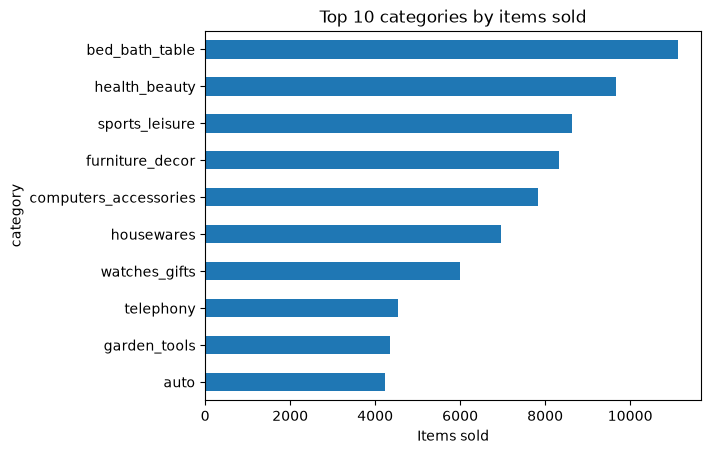

In [66]:
print("Number of categories:", len(cat))
top_items = cat.nlargest(10, "items_sold")
display(top_items[["items_sold", "item_share_%"]])

top_items["items_sold"].sort_values().plot(kind="barh", title="Top 10 categories by items sold")
plt.xlabel("Items sold")
plt.show()

**Report A1:** `bed_bath_table` sells the most items (11,115), followed by `health_beauty` (9,670), `sports_leisure` (8,641), `furniture_decor` (8,334) and `computers_accessories` (7,827).

### A2. Sales: product sales by category

,sales,sales_share_%
category,,
health_beauty,"1,258,681.34",9.26
watches_gifts,"1,205,005.68",8.87
bed_bath_table,"1,036,988.68",7.63
sports_leisure,"988,048.97",7.27
computers_accessories,"911,954.32",6.71
furniture_decor,"729,762.49",5.37
cool_stuff,"635,290.85",4.67
housewares,"632,248.66",4.65
auto,"592,720.11",4.36


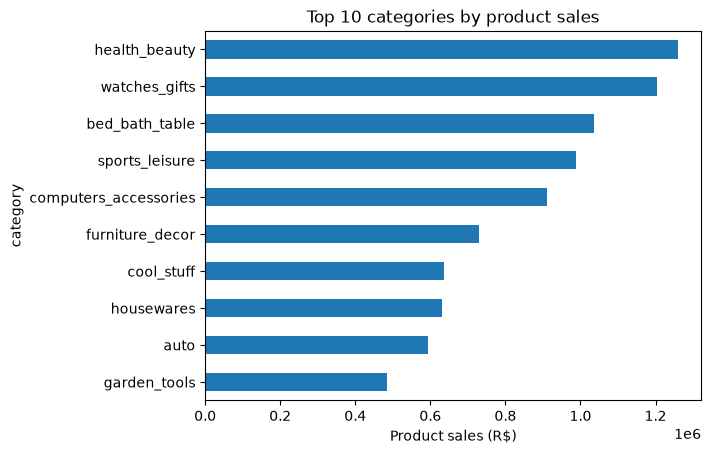

In [67]:
top_sales = cat.nlargest(10, "sales")
display(top_sales[["sales", "sales_share_%"]])

top_sales["sales"].sort_values().plot(kind="barh", title="Top 10 categories by product sales")
plt.xlabel("Product sales (R$)")
plt.show()

**Report A2:** `health_beauty` has the highest sales (R\$1.26M), followed by `watches_gifts` (R\$1.21M), `bed_bath_table` (R\$1.04M), `sports_leisure` (R\$0.99M) and `computers_accessories` (R\$0.91M).

### A3. Rank by items vs. rank by sales

In [68]:
cat["rank_gap"] = cat["rank_sales"] - cat["rank_items"]      # positive = ranks lower in sales than in items

display(cat.nsmallest(10, "rank_items")[["items_sold", "rank_items", "sales", "rank_sales", "avg_price"]])

print("High items rank, much lower sales rank:")
display(cat[(cat["rank_items"] <= 20) & (cat["rank_gap"] >= 3)][["rank_items", "rank_sales", "avg_price", "median_price"]])

print("Much higher sales rank than items rank:")
display(cat[(cat["rank_gap"] <= -5) & (cat["rank_sales"] <= 20)][["rank_items", "rank_sales", "avg_price"]])

,items_sold,rank_items,sales,rank_sales,avg_price
category,,,,,
bed_bath_table,11115,1,"1,036,988.68",3,93.30
health_beauty,9670,2,"1,258,681.34",1,130.16
sports_leisure,8641,3,"988,048.97",4,114.34
furniture_decor,8334,4,"729,762.49",6,87.56
computers_accessories,7827,5,"911,954.32",5,116.51
housewares,6964,6,"632,248.66",8,90.79
watches_gifts,5991,7,"1,205,005.68",2,201.14
telephony,4545,8,"323,667.53",14,71.21
garden_tools,4347,9,"485,256.46",10,111.63


High items rank, much lower sales rank:


,rank_items,rank_sales,avg_price,median_price
category,,,,
electronics,15,22,57.91,21.90
fashion_bags_accessories,17,24,75.25,49.00
telephony,8,14,71.21,29.99


Much higher sales rank than items rank:


,rank_items,rank_sales,avg_price
category,,,
computers,47,17,"1,098.34"
cool_stuff,12,7,167.36
musical_instruments,25,19,281.62
small_appliances,26,20,280.78
watches_gifts,7,2,201.14


**Report A3:** Nine of the ten top categories are the same in both rankings. `telephony` is 8th by items but 14th by sales. Other high-volume categories with a lower sales rank are `electronics` (15th to 22nd) and `fashion_bags_accessories` (17th to 24th): they sell many cheap items (median price R\\$22 to R\\$49). The opposite happens for `computers` (47th by items, 17th by sales), `watches_gifts` (7th to 2nd), `cool_stuff` (12th to 7th), `musical_instruments` and `small_appliances`.

### A4. Average item price

Average price of all items: 120.65


,avg_price,median_price,items_sold,rank_items,rank_sales
category,,,,,
computers,"1,098.34","1,100.00",203,47,17
small_appliances_home_oven_and_coffee,624.29,587.00,76,56,36
home_appliances_2,476.12,225.94,238,43,27
agro_industry_and_commerce,342.12,258.65,212,45,30
musical_instruments,281.62,94.84,680,25,19


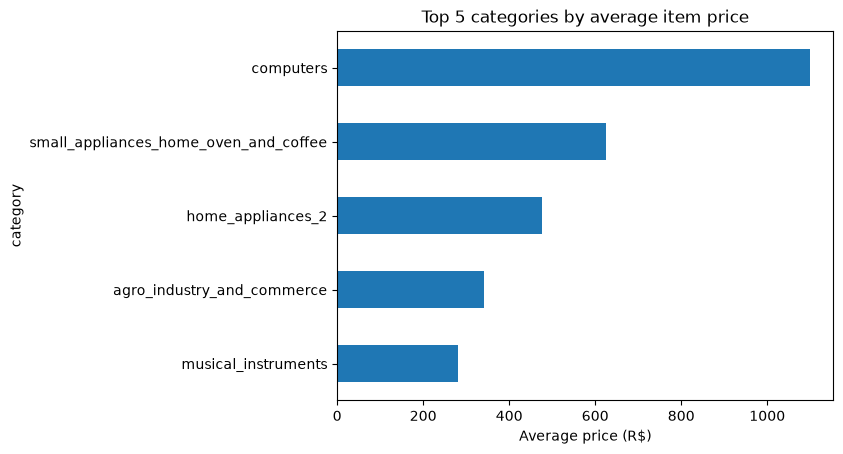

In [69]:
print("Average price of all items:", round(items["price"].mean(), 2))

top_price = cat.nlargest(5, "avg_price")
display(top_price[["avg_price", "median_price", "items_sold", "rank_items", "rank_sales"]])

top_price["avg_price"].sort_values().plot(kind="barh", title="Top 5 categories by average item price")
plt.xlabel("Average price (R$)")
plt.show()

**Report A4:** The most expensive categories are `computers` (R\\$1,098), `small_appliances_home_oven_and_coffee` (R\\$624), `home_appliances_2` (R\\$476), `agro_industry_and_commerce` (R\\$342) and `musical_instruments` (R\\$282). None of them is a top-10 category by items (their item ranks are 25 to 56) or by sales. For `musical_instruments` the median (R\\$95) is far below the mean, so a few expensive items raise its average.

### A5. Share of total sales

In [70]:
cat = cat.sort_values("sales", ascending=False)
cat["cumulative_%"] = cat["sales_share_%"].cumsum()
display(cat.head(10)[["sales", "sales_share_%", "cumulative_%"]])
print("Top 5 categories share of sales:", round(cat["sales_share_%"].head(5).sum(), 2), "%")

# Categories with at least 1% of sales whose sales share is 30% higher than their item share
display(cat[(cat["sales_share_%"] >= 1) & (cat["sales_share_%"] > 1.3 * cat["item_share_%"])][["sales_share_%", "item_share_%"]])

,sales,sales_share_%,cumulative_%
category,,,
health_beauty,"1,258,681.34",9.26,9.26
watches_gifts,"1,205,005.68",8.87,18.13
bed_bath_table,"1,036,988.68",7.63,25.76
sports_leisure,"988,048.97",7.27,33.03
computers_accessories,"911,954.32",6.71,39.74
furniture_decor,"729,762.49",5.37,45.10
cool_stuff,"635,290.85",4.67,49.78
housewares,"632,248.66",4.65,54.43
auto,"592,720.11",4.36,58.79


Top 5 categories share of sales: 39.74 %


,sales_share_%,item_share_%
category,,
watches_gifts,8.87,5.32
cool_stuff,4.67,3.37
office_furniture,2.02,1.50
computers,1.64,0.18
musical_instruments,1.41,0.60
small_appliances,1.40,0.60


**Report A5:** The top 5 categories (`health_beauty` 9.26%, `watches_gifts` 8.87%, `bed_bath_table` 7.63%, `sports_leisure` 7.27%, `computers_accessories` 6.71%) make **39.74%** of product sales; the top 10 make 62.36%. `watches_gifts` (8.87% of sales from 5.32% of items) and `cool_stuff` contribute more than their volume suggests. `computers` makes 1.64% of sales from only 0.18% of items.

### A6. Items sold vs. product sales

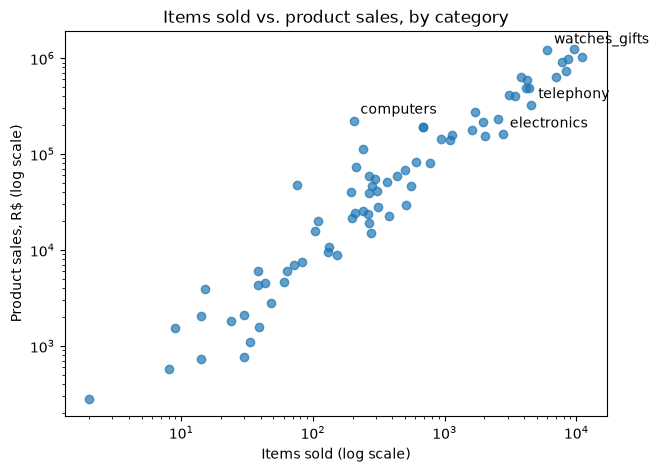

Correlation: 0.95


In [71]:
plt.figure(figsize=(7, 5))
plt.scatter(cat["items_sold"], cat["sales"], alpha=0.7)
plt.xscale("log")
plt.yscale("log")
for name in ["watches_gifts", "telephony", "computers", "electronics"]:      # label a few categories
    plt.annotate(name, (cat.loc[name, "items_sold"], cat.loc[name, "sales"]), xytext=(5, 5), textcoords="offset points")
plt.xlabel("Items sold (log scale)")
plt.ylabel("Product sales, R$ (log scale)")
plt.title("Items sold vs. product sales, by category")
plt.show()

print("Correlation:", round(cat["items_sold"].corr(cat["sales"]), 2))

**Report A6:** Categories with more items usually have more sales (correlation 0.95), but price moves them away from the trend. `telephony` and `electronics` have many items but low sales; `computers` and `watches_gifts` have fewer items but high sales.

### A. Business conclusion
- **By items:** `bed_bath_table`, `health_beauty`, `sports_leisure`, `furniture_decor`, `computers_accessories` lead.
- **By sales:** `health_beauty`, `watches_gifts`, `bed_bath_table`, `sports_leisure`, `computers_accessories` lead. `watches_gifts` is worth more than its volume suggests.
- **Why items alone can mislead:** prices differ a lot between categories. `telephony` is 8th by items but 14th by sales, and `computers` is 47th by items but 17th by sales. Product sales are not profit, so they should also be read together with margins.

## Part B: Payments

### B0. Records and orders

In [72]:
print("Payment records:", len(payments), "| unique orders:", payments["order_id"].nunique())

per_order = payments.groupby("order_id").agg(records=("payment_sequential", "size"), methods=("payment_type", "nunique"))
print("Orders with more than 1 record:", (per_order["records"] > 1).sum())
print("Orders paid with more than 1 method:", (per_order["methods"] > 1).sum())

Payment records: 103886 | unique orders: 99440
Orders with more than 1 record: 2961
Orders paid with more than 1 method: 2246


**Report B0:** There are 103,886 payment records for 99,440 orders. 2,961 orders have several records and 2,246 orders use more than one method, so records and orders are counted separately. Payment value includes freight, so it is not the same as the product sales of Part A.

### B1. Payment methods: records, total value and average value (Q1 to Q3)

,records,orders,total_value,avg_value,records_%,value_%
payment_type,,,,,,
credit_card,76795,76505,"12,542,084.19",163.32,73.92,78.34
boleto,19784,19784,"2,869,361.27",145.03,19.04,17.92
voucher,5775,3866,"379,436.87",65.70,5.56,2.37
debit_card,1529,1528,"217,989.79",142.57,1.47,1.36
not_defined,3,3,0.00,0.00,0.00,0.00


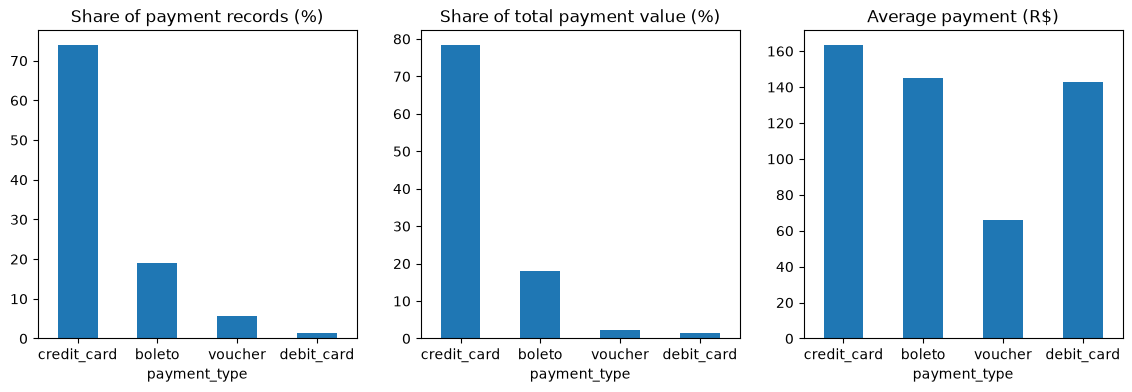

In [73]:
by_type = payments.groupby("payment_type").agg(records=("order_id", "size"), orders=("order_id", "nunique"),
                                               total_value=("payment_value", "sum"), avg_value=("payment_value", "mean"))
by_type["records_%"] = by_type["records"] / by_type["records"].sum() * 100
by_type["value_%"] = by_type["total_value"] / by_type["total_value"].sum() * 100
by_type = by_type.sort_values("records", ascending=False)
display(by_type)

main = by_type.drop("not_defined")        # 3 records with value 0, left out of the charts
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
main["records_%"].plot(kind="bar", ax=axes[0], rot=0, title="Share of payment records (%)")
main["value_%"].plot(kind="bar", ax=axes[1], rot=0, title="Share of total payment value (%)")
main["avg_value"].plot(kind="bar", ax=axes[2], rot=0, title="Average payment (R$)")
plt.show()

**Report B1:** `credit_card` is the most used method (76,795 records, 73.92%), then `boleto` (19.04%), `voucher` (5.56%) and `debit_card` (1.47%). The most used method also has the highest total value (R$12.54M, 78.34%) and the highest average payment (R$163). `voucher` has a low average (R$66). It has 5,775 records but only 3,866 orders, so one order can have several voucher records.

### B2. Installments (Q4)

payment_installments
1    50.58
2    11.95
3    10.07
4     6.83
10    5.13
Name: count, dtype: float64

1 installment: 52546 records (50.6%) | 2 or more: 51338
Missing installments (2 invalid zeros set to missing when loading): 2


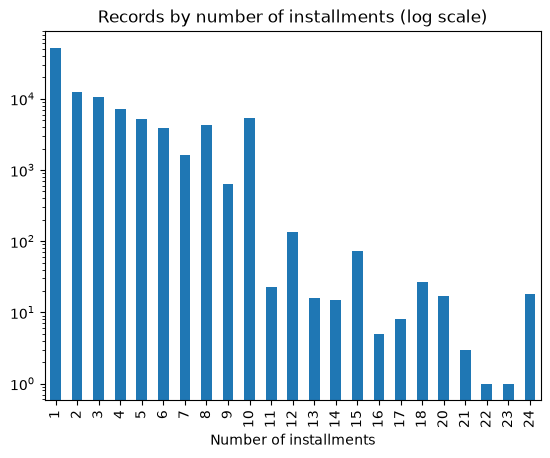

In [74]:
inst = payments["payment_installments"].dropna().astype(int).value_counts().sort_index()
display((inst.nlargest(5) / len(payments) * 100).round(2))        # most common counts, % of records

one = (payments["payment_installments"] <= 1).sum()
print(f"1 installment: {one} records ({one / len(payments):.1%}) | 2 or more: {(payments['payment_installments'] > 1).sum()}")
print("Missing installments (2 invalid zeros set to missing when loading):", payments["payment_installments"].isna().sum())

inst.plot(kind="bar", logy=True, title="Records by number of installments (log scale)")
plt.xlabel("Number of installments")
plt.show()

**Report B2:** Half of the records (52,546; 50.58%) are paid in one installment. The next most common are 2 installments (11.95%) and 3 (10.07%). 10 installments (5.13%) is unusually common compared with 9 or 11. No record has zero installments after cleaning.

### B3. Payment amount vs. installments (Q5)

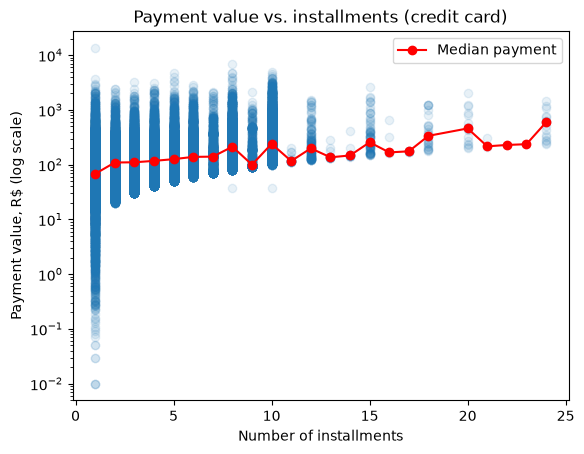

payment_installments
1     67.87
2    109.42
3    110.42
4    117.18
5    125.97
6    138.55
7    140.07
8    212.69
9     99.92
10   239.74
Name: payment_value, dtype: float64

In [75]:
cc = payments[payments["payment_type"] == "credit_card"]        # only credit card has more than 1 installment (see B4)
medians = cc.groupby("payment_installments")["payment_value"].median()

plt.scatter(cc["payment_installments"], cc["payment_value"], alpha=0.1)
plt.plot(medians.index, medians.values, color="red", marker="o", label="Median payment")
plt.yscale("log")
plt.xlabel("Number of installments")
plt.ylabel("Payment value, R$ (log scale)")
plt.title("Payment value vs. installments (credit card)")
plt.legend()
plt.show()

display(medians.head(10))

**Report B3:** Larger payments tend to have more installments: the rank correlation is 0.48 (moderate) and the median payment rises from R$68 (1 installment) to R$110 (3), R$139 (6) and R$240 (10). The pattern is not strict: the points are widely spread at every installment count, and the median is not always increasing (R$100 at 9 installments, below R$213 at 8).

### B4. Payment method vs. installments (Q6)

,min,median,mean,max
payment_type,,,,
boleto,1,1.00,1.00,1
credit_card,1,3.00,3.51,24
debit_card,1,1.00,1.00,1
not_defined,1,1.00,1.00,1
voucher,1,1.00,1.00,1


payment_installments,1,2-3,4-6,7-10,11+
payment_type,,,,,
boleto,100.00,0.00,0.00,0.00,0.00
credit_card,33.15,29.79,21.17,15.45,0.44
debit_card,100.00,0.00,0.00,0.00,0.00
not_defined,100.00,0.00,0.00,0.00,0.00
voucher,100.00,0.00,0.00,0.00,0.00


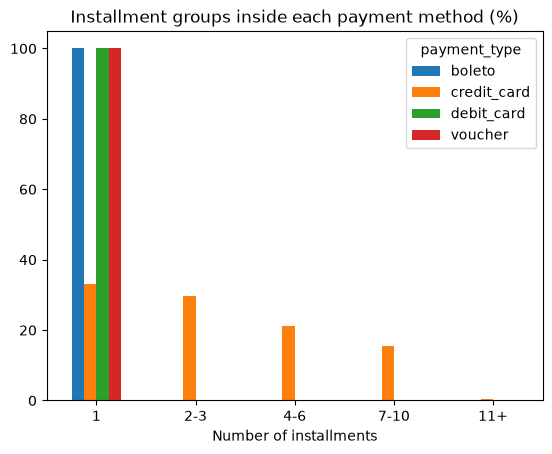

In [76]:
display(payments.groupby("payment_type")["payment_installments"].agg(["min", "median", "mean", "max"]))

groups = pd.cut(payments["payment_installments"], [0, 1, 3, 6, 10, 24], labels=["1", "2-3", "4-6", "7-10", "11+"])
share = pd.crosstab(payments["payment_type"], groups, normalize="index") * 100
display(share)

share.drop("not_defined").T.plot(kind="bar", rot=0, title="Installment groups inside each payment method (%)")
plt.xlabel("Number of installments")
plt.show()

**Report B4:** `boleto`, `debit_card` and `voucher` are always paid in 1 installment. Only `credit_card` has installment plans (median 3, mean 3.51, maximum 24): about 33% of its records have 1 installment, 30% have 2 to 3, 21% have 4 to 6, 15% have 7 to 10 and under 1% have 11 or more.

### B. Business conclusion
- **Most used methods:** credit card (73.92% of records, 78.34% of value) and boleto (19.04% of records).
- **Is the amount related to the installments?** Yes, for credit card payments (correlation 0.48, median R$68 at 1 installment to R$240 at 10). It is not the only factor. Other methods have no installment choice.

## Final Report

**Data and method.** Cleaned tables from `Data/Processed` were used. Items were joined to products (row count and total price unchanged), and uncategorized products were kept in an `unknown` group. Payments were analyzed alone, counting records and orders separately. Total product sales are R$13.59M (112,650 items); total payment value is R$16.01M (103,886 records, 99,440 orders).

**Part A: product categories**
- Top by items: `bed_bath_table`, `health_beauty`, `sports_leisure`. Top by sales: `health_beauty`, `watches_gifts`, `bed_bath_table`.
- The top 5 categories by sales make 39.74% of product sales (top 10: 62.36%).
- Categories with many cheap items (`telephony`, `electronics`, `fashion_bags_accessories`) rank lower by sales; expensive categories (`computers`, `watches_gifts`) rank higher.
- The most expensive categories (`computers`, `home_appliances_2`, ...) are small in volume and sales.

**Part B: payments**
- Credit card dominates: 73.92% of records and 78.34% of value, with the highest average payment (R$163). Boleto is second (19.04% of records).
- 50.58% of records use 1 installment. Only credit card has installment plans (up to 24, median 3).
- For credit card, larger payments tend to have more installments (correlation 0.48), but the relationship is not strict.

**Limitations**
- Product sales and payment values are not profit. Payment value includes freight, so Parts A and B totals are not comparable.
- Averages can be raised by a few expensive items (for example `musical_instruments`).
- Correlation shows association, not cause. No analysis over time was done.